# Retail Sales Exploratory Data Analysis

### Project Overview

This project explores the Sample Superstore dataset using Python, Pandas, NumPy, and Matplotlib to identify sales trends, profit patterns, customer segments, and regional performance.

**Dataset:** Sample Superstore (Kaggle)
https://www.kaggle.com/datasets/vivek468/superstore-dataset-final

**Objective:** To analyze retail sales data and discover meaningful business insights through exploratory data analysis and visualization.

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [50]:
from google.colab import files

uploaded = files.upload()

Saving Sample - Superstore.csv.zip to Sample - Superstore.csv (3).zip


In [51]:
import zipfile

zip_filename = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall('superstore_data')

In [52]:
df = pd.read_csv(
    'superstore_data/Sample - Superstore.csv',
    encoding='latin1'
)

## 1. Dataset Overview

In [53]:
print("Dataset Shape:", df.shape)

Dataset Shape: (9994, 21)


In [54]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [55]:
df.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9989,9990,CA-2014-110422,1/21/2014,1/23/2014,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.248,3,0.2,4.1028
9990,9991,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,0.0,15.6332
9991,9992,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.576,2,0.2,19.3932
9992,9993,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,0.0,13.3200
9993,9994,CA-2017-119914,5/4/2017,5/9/2017,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,...,92683,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.160,2,0.0,72.9480


In [56]:
print(df.columns)

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')


In [57]:
print(df.dtypes)

Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [59]:
print("Memory Usage:")
print(df.memory_usage(deep=True).sum() / 1024**2, "MB")

Memory Usage:
9.206507682800293 MB


## 2. Missing Value Analysis

In [60]:
missing_values = df.isnull().sum()

print(missing_values)

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [61]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Row ID           0.0
Order ID         0.0
Order Date       0.0
Ship Date        0.0
Ship Mode        0.0
Customer ID      0.0
Customer Name    0.0
Segment          0.0
Country          0.0
City             0.0
State            0.0
Postal Code      0.0
Region           0.0
Product ID       0.0
Category         0.0
Sub-Category     0.0
Product Name     0.0
Sales            0.0
Quantity         0.0
Discount         0.0
Profit           0.0
dtype: float64


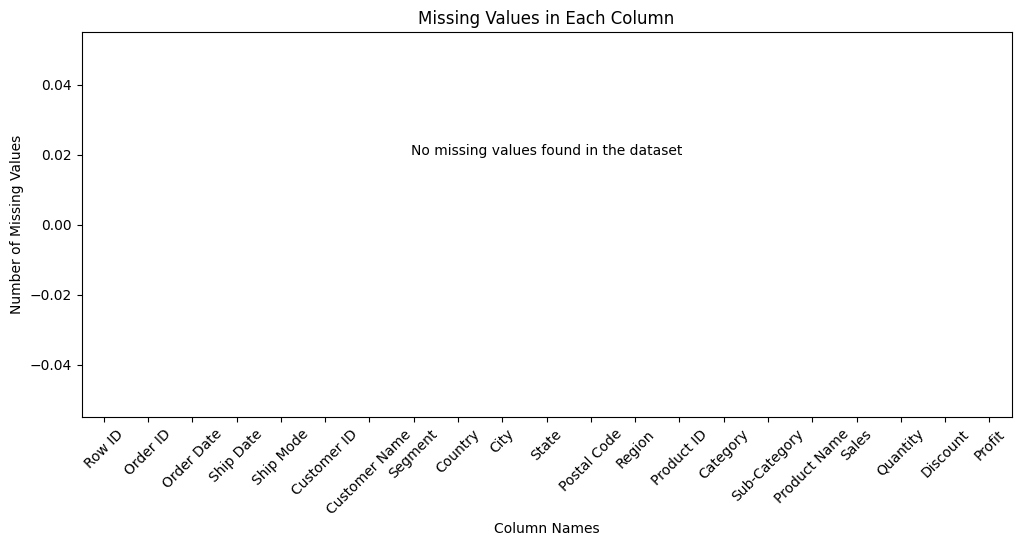

In [62]:
plt.figure(figsize=(12, 5))

missing_values.plot(kind='bar')

plt.title('Missing Values in Each Column')
plt.xlabel('Column Names')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45)

plt.text(
    10, 0.02,
    'No missing values found in the dataset',
    ha='center'
)

plt.show()

### Interpretation of Missing Value Analysis

The dataset contains no missing values across its 21 columns. Therefore, no missing-value treatment was required.

## 3. Summary Statistics

In [63]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [64]:
df[['Sales', 'Quantity', 'Discount', 'Profit']].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [65]:
df[['Sales', 'Quantity', 'Discount', 'Profit']].median()

,0
Sales,54.4900
Quantity,3.0000
Discount,0.2000
Profit,8.6665


### Interpretation of Summary Statistics

- The dataset contains 9,994 records.
- The average sales value is 229.86, while the median is 54.49, indicating that some high-value sales increase the average.
- The average quantity per record is approximately 3.79 products.
- The average discount is approximately 15.6%.
- The average profit is 28.66, but the minimum profit is -6,599.98, indicating that some transactions resulted in losses.

These statistics provide an initial understanding of sales, discounts, quantities and profitability.

## 4. Categorical Analysis

In [66]:
df['Category'].value_counts()

,count
Category,
Office Supplies,6026
Furniture,2121
Technology,1847


### Interpretation of Product Category

- Office Supplies has the highest number of records, with 6,026 entries.
- Furniture has 2,121 entries.
- Technology has the lowest number of records, with 1,847 entries.

This shows that Office Supplies is the most frequently represented product category in the dataset.

In [67]:
df['Region'].value_counts()

,count
Region,
West,3203
East,2848
Central,2323
South,1620


In [68]:
df['Segment'].value_counts()

,count
Segment,
Consumer,5191
Corporate,3020
Home Office,1783


In [69]:
df['Ship Mode'].value_counts()

,count
Ship Mode,
Standard Class,5968
Second Class,1945
First Class,1538
Same Day,543


### Interpretation of Categorical Analysis

- Region: West has the highest records (3,203), while South has the lowest (1,620).
- Customer Segment: Consumer is the largest segment (5,191), while Home Office is the smallest (1,783).
- Shipping Mode: Standard Class is the most used (5,968), while Same Day is the least used (543).

Overall, Consumer customers, the West region, and Standard Class dominate the dataset.

## 5. Data Visualization

In [70]:
category_sales = df.groupby('Category')['Sales'].sum()
print(category_sales)

Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64


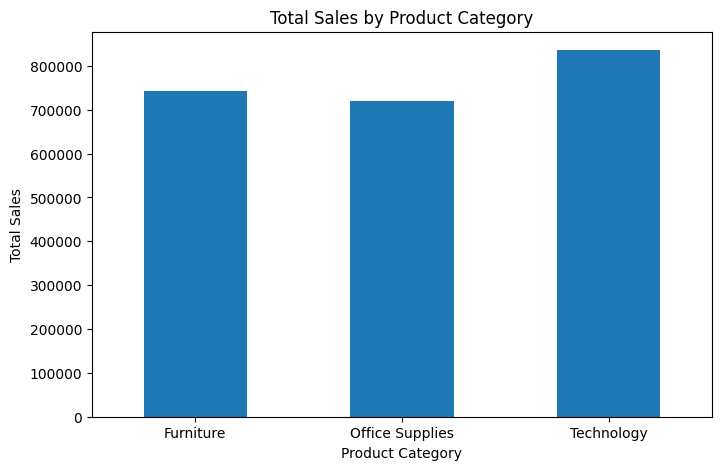

In [71]:
plt.figure(figsize=(8, 5))
category_sales.plot(kind='bar')

plt.title('Total Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.show()

### Interpretation of Total Sales by Product Category

- Technology: Has the highest total sales (836,154.03).
- Furniture: Generates total sales of 741,999.80.
- Office Supplies: Has the lowest total sales (719,047.03).

Overall, Technology is the top-performing product category in terms of total sales.


Region
Central     39706.3625
East        91522.7800
South       46749.4303
West       108418.4489
Name: Profit, dtype: float64


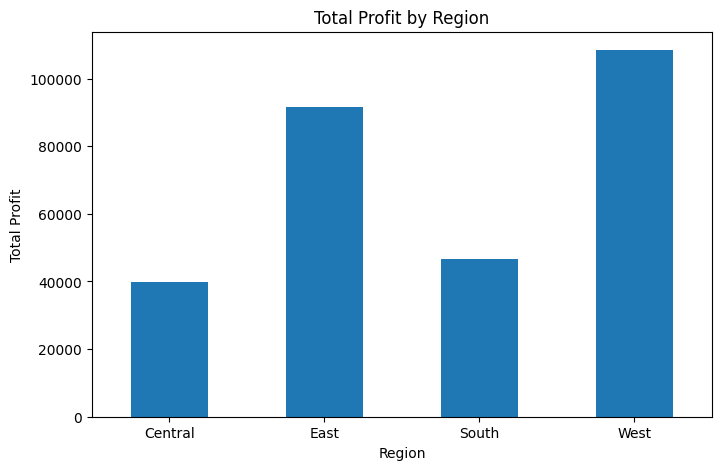

In [72]:
region_profit = df.groupby('Region')['Profit'].sum()
print(region_profit)

plt.figure(figsize=(8, 5))
region_profit.plot(kind='bar')

plt.title('Total Profit by Region')
plt.xlabel('Region')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.show()

### Interpretation of Total Profit by Region

- West: Recorded the highest profit of 108,418.45.
- East: Generated a profit of 91,522.78.
- South: Recorded a profit of 46,749.43.
- Central: Recorded the lowest profit of 39,706.36.

Overall, the West region contributed the most to total profit, while the Central region had the lowest profitability.

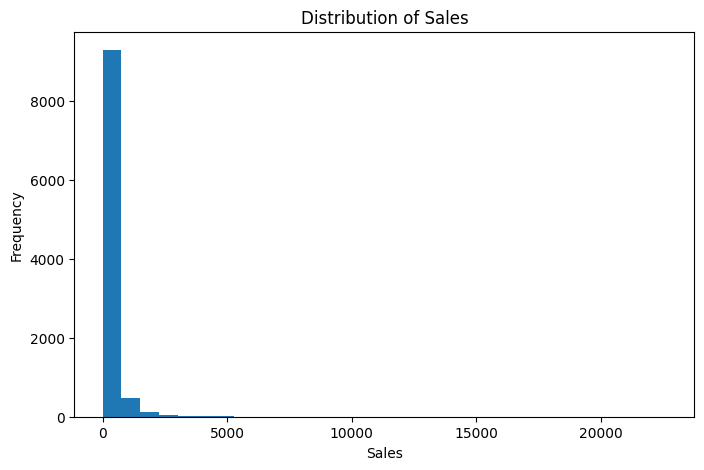

In [73]:
plt.figure(figsize=(8, 5))
plt.hist(df['Sales'], bins=30)

plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')

plt.show()

### Interpretation of Sales Distribution
- Most sales transactions are concentrated in the lower sales-value ranges.
- Only a small number of transactions have very high sales values.
Overall, the distribution is right-skewed, indicating that high-value sales transactions are relatively rare.

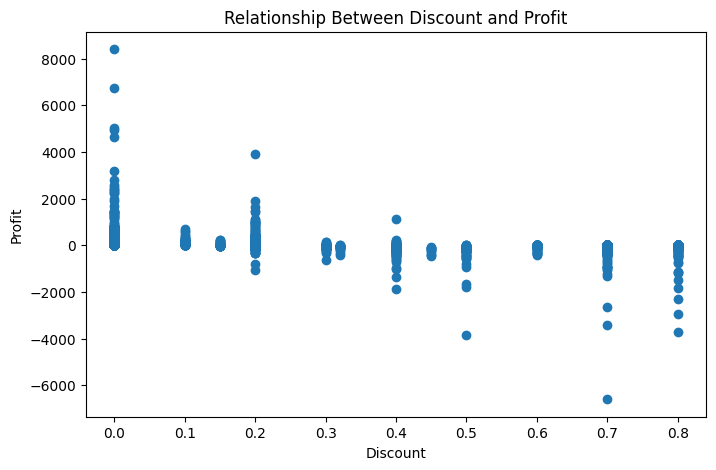

In [74]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Discount'], df['Profit'])

plt.title('Relationship Between Discount and Profit')
plt.xlabel('Discount')
plt.ylabel('Profit')

plt.show()

### Interpretation of Relationship Between Discount and Profit

- Transactions with no discount generally show higher profits.
- As discounts increase, profits tend to decrease.
- Some high-discount transactions result in losses.

Overall, offering higher discounts can reduce the profit earned by the business.

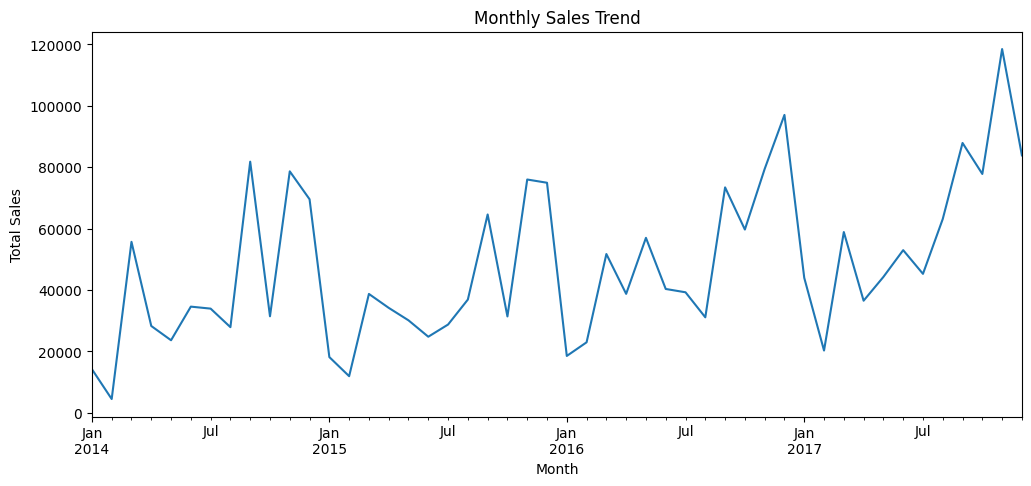

In [75]:
df['Order Date'] = pd.to_datetime(df['Order Date'])

monthly_sales = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum()

plt.figure(figsize=(12, 5))
monthly_sales.plot(kind='line')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.show()

### Interpretation of Monthly Sales Trend
- Sales fluctuate significantly from month to month.
- Overall, sales show an increasing trend from 2014 to 2017.
- The highest sales peak occurs towards the end of 2017.
Overall, the business shows growth in sales over the four-year period despite monthly fluctuations.

### Key Findings from Exploratory Data Analysis

1. **Technology Leads in Sales:** Technology is the highest-performing product category, generating total sales of 836,154.03, indicating strong customer demand.

2. **West Region Drives Profitability:** The West region contributes the highest profit (108,418.45), while the Central region records the lowest (39,706.36), highlighting regional differences in business performance.

3. **Sales Are Unevenly Distributed:** Most transactions fall within lower sales-value ranges, while a small number of high-value transactions contribute to the overall sales distribution.

4. **Discounts Affect Profitability:** Higher discount levels are generally associated with lower profits and increased losses, suggesting the need for better discount strategies.

5. **Consistent Long-Term Sales Growth:** Despite monthly fluctuations, the overall sales trend increases from 2014 to 2017, indicating positive business growth over the analyzed period.

### Overall Conclusion

The analysis highlights Technology as the leading sales category and the West as the most profitable region. It also reveals opportunities to improve discount strategies and strengthen regional performance.